# Historical calibration reference

This notebook documents the original calibration procedure. The original CHA-level records are not distributed, and the output displaying those records has been removed. Re-running calibration requires separately authorized access to the original data.

The public package retains calibrated parameters, simulation results, distance data and inventory data. Use `code/notebooks/paper_results.ipynb` from the repository root for figure and table reproduction from those saved inputs. Other outputs here describe historical calibration settings.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

In [4]:
config_path = "../configs/baseline/"

In [ ]:
K = 7
p = 0.89
tau = 1 # travel cost per mile
Q0 = 142
T = 28 # number of weeks in a month
# hf_cha_ratio = 0.72

In [5]:
c_df = pd.DataFrame(np.ones((K+1,1)))
c_df.to_csv(os.path.join(config_path, "c.csv"), index=False, header=False)

In [7]:
distance = pd.read_excel("distance.xlsx")[["distance"]]
cha_distance = distance * tau
hf_distance = pd.DataFrame([[0.0]], columns=["distance"])
d_df = pd.concat([hf_distance, cha_distance], ignore_index=True)
d_df.to_csv(os.path.join(config_path, "d.csv"), index=False, header=False)
d_df

,distance
0,0.00
1,11.00
2,3.80
3,3.00
4,0.25
5,5.00
6,5.00
7,0.50


In [9]:
h_df = pd.DataFrame(np.zeros((K+1,1)))
h_df.to_csv(os.path.join(config_path, "h.csv"), index=False, header=False)
h_df

,0
0,0.0
1,0.0
2,0.0
3,0.0
4,0.0
5,0.0
6,0.0
7,0.0


In [10]:
p_df = pd.DataFrame(np.ones((K,1)) * p)
p_df.to_csv(os.path.join(config_path, "p.csv"), index=False, header=False)
p_df


,0
0,0.89
1,0.89
2,0.89
3,0.89
4,0.89
5,0.89
6,0.89


In [8]:
eta_0 = 28 * Q0 / ((K+1) * T)
eta_k = 14 * Q0 / ((K+1) * T)
eta_df = pd.DataFrame(np.array([eta_0] + [eta_k] * K))
eta_df.to_csv(os.path.join(config_path, "eta.csv"), index=False, header=False)
# eta_df

## Demand Parameters

In [ ]:
cha_data = pd.read_excel('CHA_weekly.xlsx')
cha_data = cha_data.sort_values(by=['CHA ID','unique_id','household visits'])
cha_data[['CHA ID', 'month', 'week', 'Malaria (RTD+)', 
            'Malaria treated (2-11 months)', 'Malaria treated (1-5 years)',
            'Referred to Health Facility', 'unique_id']]

In [36]:
n_cha = np.floor(cha_data['household visits'].mean()).astype(int)
n_hf = 219
print("Number of CHA visits: ", n_cha)
print("Number of HF visits: ", n_hf)


Number of CHA visits:  28
Number of HF visits:  219


In [37]:
# cha_data_visit = \
#     cha_data[['CHA ID', 'household visits', 'unique_id']].pivot(
#     index='unique_id',
#     columns='CHA ID',
#     values='household visits'
# ).reset_index(drop=True)
# cha_data_visit

In [33]:
cha_data_use = cha_data[['CHA ID', 'Malaria (RTD+)', 'unique_id']].pivot(
    index='unique_id',
    columns='CHA ID',
    values='Malaria (RTD+)'
).reset_index(drop=True)
cha_data_week_sum = cha_data_use.sum(axis=1)
theta = cha_data_week_sum/ (K * n_cha)
# cha_data_use
# cha_data_week_sum
theta

0     0.000000
1     0.000000
2     0.000000
3     0.000000
4     0.025510
5     0.051020
6     0.010204
7     0.015306
8     0.020408
9     0.030612
10    0.015306
11    0.015306
12    0.071429
13    0.045918
14    0.020408
15    0.020408
16    0.030612
17    0.020408
18    0.005102
19    0.020408
20    0.005102
21    0.025510
22    0.015306
23    0.010204
24    0.015306
25    0.010204
26    0.000000
27    0.000000
28    0.005102
29    0.005102
30    0.000000
31    0.000000
32    0.005102
33    0.000000
34    0.000000
35    0.000000
36    0.000000
37    0.000000
38    0.000000
39    0.000000
40    0.000000
41    0.000000
42    0.000000
43    0.000000
44    0.000000
45    0.000000
46    0.000000
47    0.000000
dtype: float64

In [48]:
begin_week = 5
end_week = 26
theta_use = theta[begin_week-1:end_week].reset_index(drop=True)
n_list = np.array([n_hf]+[n_cha]*K)
# n_list
mu_df = pd.DataFrame(np.outer(theta_use, n_list))
gamma_df = pd.DataFrame(np.outer(theta_use*(1-theta_use), n_list))
# mu_df
theta_use

0     0.025510
1     0.051020
2     0.010204
3     0.015306
4     0.020408
5     0.030612
6     0.015306
7     0.015306
8     0.071429
9     0.045918
10    0.020408
11    0.020408
12    0.030612
13    0.020408
14    0.005102
15    0.020408
16    0.005102
17    0.025510
18    0.015306
19    0.010204
20    0.015306
21    0.010204
dtype: float64

$\theta(n)$


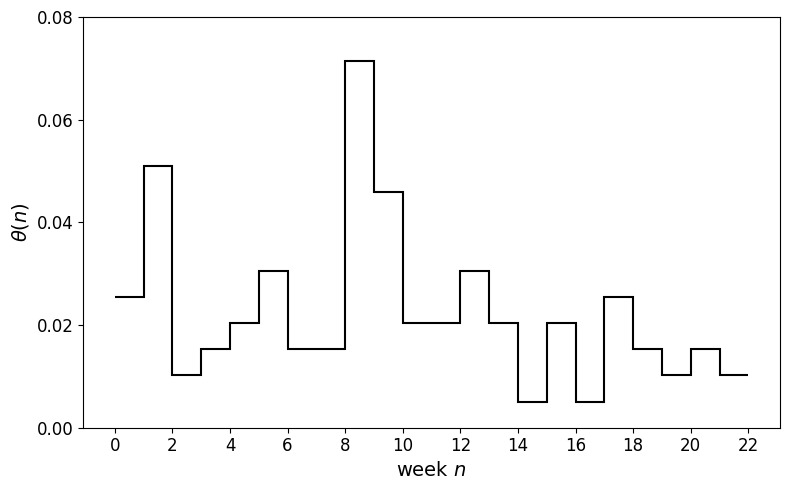

In [64]:
plt.figure(figsize=(8, 5))
plt.stairs(theta_use.values, np.arange(len(theta_use)+1), color='black', linewidth=1.5, baseline=None)

plt.ylabel(r'$\theta(n)$', fontsize=14)
plt.xlabel(r'week $n$', fontsize=14)

print(r'$\theta(n)$')

x_ticks = np.arange(0,len(theta_use)+2,2)
y_ticks = np.arange(0,0.1,0.02)
plt.xticks(x_ticks, fontsize=12)
plt.yticks(y_ticks, fontsize=12)
plt.tight_layout()
plt.savefig('calibrated_theta.pdf', bbox_inches='tight', dpi=150)
plt.show()

In [87]:
d_bar = mu_df.sum().sum()
print("mean total demand:", d_bar)
print("cha mean total demand", mu_df.iloc[:,1:].sum().sum())
print("hf mean total demand", mu_df.iloc[:,:1].sum().sum())
print("ratio to initial inventory", Q0/d_bar)
# cha_data_week_sum[begin_week-1:end_week].sum() * (n_cha*K+n_hf)/ (n_cha*K)


mean total demand: 207.5
cha mean total demand 98.0
hf mean total demand 109.50000000000001
ratio to initial inventory 0.6843373493975904


In [85]:
distance = pd.read_excel("distance.xlsx")[["distance"]]
distance

w = 0.68
kappa = 0.15
p = 0.89
u = 8 * 8 * w
print("u", u)
r = 1 * 8 * w + 2 * kappa * distance
print(f"r = {8 * w} + {2 * kappa} * distance \n", r.T.values[0])
c_hf = u
c_cha = (1 - p) * u + p * r
print("c_hf", c_hf)
print("c_cha", c_cha.T.values[0])
c = np.array(list([c_hf]) + list(c_cha.T.values[0]))
c

u 43.52
r = 5.44 + 0.3 * distance 
 [8.74  6.58  6.34  5.515 6.94  6.94  5.59 ]
c_hf 43.52
c_cha [12.5658  10.6434  10.4298   9.69555 10.9638  10.9638   9.7623 ]


array([43.52   , 12.5658 , 10.6434 , 10.4298 ,  9.69555, 10.9638 ,
       10.9638 ,  9.7623 ])

In [88]:
mu_df

,0,1,2,3,4,5,6,7
0,5.586735,0.714286,0.714286,0.714286,0.714286,0.714286,0.714286,0.714286
1,11.173469,1.428571,1.428571,1.428571,1.428571,1.428571,1.428571,1.428571
2,2.234694,0.285714,0.285714,0.285714,0.285714,0.285714,0.285714,0.285714
3,3.352041,0.428571,0.428571,0.428571,0.428571,0.428571,0.428571,0.428571
4,4.469388,0.571429,0.571429,0.571429,0.571429,0.571429,0.571429,0.571429
5,6.704082,0.857143,0.857143,0.857143,0.857143,0.857143,0.857143,0.857143
6,3.352041,0.428571,0.428571,0.428571,0.428571,0.428571,0.428571,0.428571
7,3.352041,0.428571,0.428571,0.428571,0.428571,0.428571,0.428571,0.428571
8,15.642857,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
9,10.056122,1.285714,1.285714,1.285714,1.285714,1.285714,1.285714,1.285714


In [91]:
# CHA bounds
mu = mu_df.values
gamma = gamma_df.values
beta = 1 - Q0 / d_bar

eta = np.zeros(mu.shape[1])
eta[1:] = np.max(mu[:, 1:] + 2 * np.sqrt(gamma[:, 1:]), axis=0)

# HF bound

eta[0] = np.max(
    mu[:, 0]
    + p * beta * mu[:, 1:].sum(axis=1)
    + 2 * np.sqrt(gamma[:, 0] + (p ** 2) * (beta ** 2) * gamma[:, 1:].sum(axis=1))
)
eta

array([27.46310782,  4.72554058,  4.72554058,  4.72554058,  4.72554058,
        4.72554058,  4.72554058,  4.72554058])